<a href="https://colab.research.google.com/github/shingihorton/IS4487_Portfolio/blob/main/IS4487_Shingi_assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [ ]:
#Here, I import the necessary python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

#Importing the csv file
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/refs/heads/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
#Displaying first few rows
display (df.head())
#Dispaying summary statistics
display (df.describe())



,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.The second row with a lead time of 737 days stands out to me. It seems unusual and it is also the max on the summary statistics. If this is correct, someone booked 2 years in advance.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [ ]:
# 1. Select the specified columns
features = ['stays_in_weekend_nights', 'stays_in_week_nights', 'booking_changes', 'total_of_special_requests']

# Ensure we work with a clean subset
prepared_df = df[features].copy()

# 2. Drop missing values
prepared_df = prepared_df.dropna()

# 3. Correct data types to integers
for col in features:
    prepared_df[col] = prepared_df[col].astype(int)

# 4. Remove duplicate rows
prepared_df = prepared_df.drop_duplicates()

# 5. Remove outliers using IQR (Interquartile Range) for each feature
for col in features:
    Q1 = prepared_df[col].quantile(0.25)
    Q3 = prepared_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    prepared_df = prepared_df[(prepared_df[col] >= lower_bound) & (prepared_df[col] <= upper_bound)]

# 6. Standardize large values (over 100) using StandardScaler
# Let's inspect maximum values to decide on scaling
print("Max values before scaling:")
print(prepared_df.max())

# Identify columns with values exceeding 100
columns_to_scale = [col for col in features if prepared_df[col].max() > 100]

if columns_to_scale:
    scaler = StandardScaler()
    prepared_df[columns_to_scale] = scaler.fit_transform(prepared_df[columns_to_scale])
    print(f"\nStandardized columns: {columns_to_scale}")
else:
    print("\nNo selected columns have values exceeding 100, so standard scaling was skipped based on the criteria.")

# Display cleaned dataframe summary
print("\nPrepared Dataframe Info:")
print(prepared_df.info())
display(prepared_df.head())

Max values before scaling:
stays_in_weekend_nights       8
stays_in_week_nights         17
booking_changes              10
total_of_special_requests     5
dtype: int64

No selected columns have values exceeding 100, so standard scaling was skipped based on the criteria.

Prepared Dataframe Info:
<class 'pandas.core.frame.DataFrame'>
Index: 882 entries, 0 to 119268
Data columns (total 4 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   stays_in_weekend_nights    882 non-null    int64
 1   stays_in_week_nights       882 non-null    int64
 2   booking_changes            882 non-null    int64
 3   total_of_special_requests  882 non-null    int64
dtypes: int64(4)
memory usage: 34.5 KB
None


,stays_in_weekend_nights,stays_in_week_nights,booking_changes,total_of_special_requests
0,0,0,3,0
1,0,0,4,0
2,0,1,0,0
4,0,2,0,1
6,0,2,0,0


In [ ]:
# The first column looks strange so I am inspecting
columns_to_display = ['stays_in_weekend_nights', 'stays_in_week_nights', 'booking_changes', 'total_of_special_requests', 'is_canceled']

# Display the subset
display(df[columns_to_display].head())

,stays_in_weekend_nights,stays_in_week_nights,booking_changes,total_of_special_requests,is_canceled
0,0,0,3,0,0
1,0,0,4,0,0
2,0,1,0,0,0
3,0,1,0,0,0
4,0,2,0,1,0


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I chose stays_in_weekend_nights, stays_in_week_nights, booking_changes and total_of_special_requests. I picked these features because they can help predict customer behavior about their preferred time of stay and if they are more likely to have a special request.

2. I think maybe our week nights will have more special requests and maybe more booking changes.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

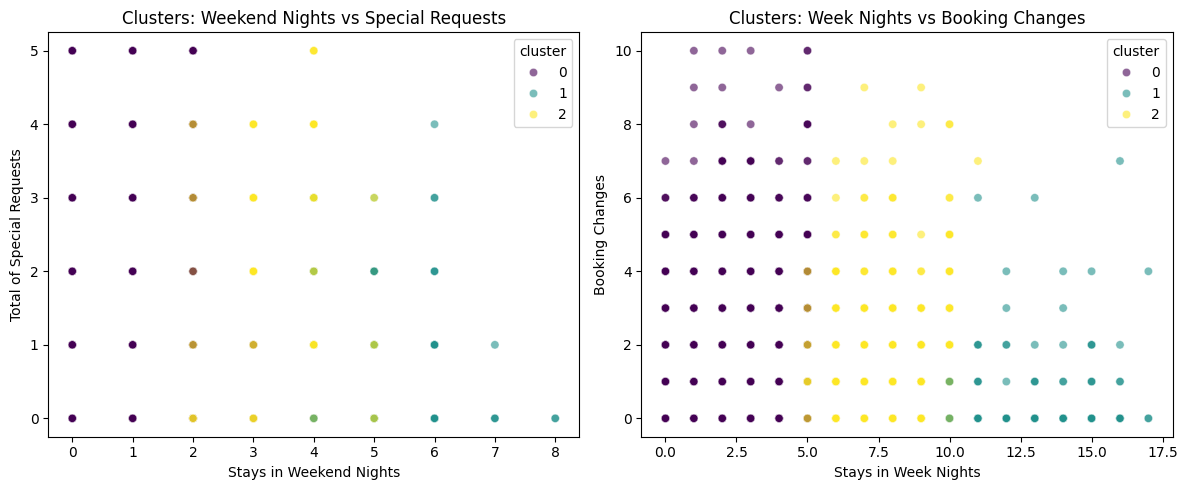


--- Cluster Averages (Summary Table) ---


,stays_in_weekend_nights,stays_in_week_nights,booking_changes,total_of_special_requests
cluster,,,,
0,1.001980,2.566337,2.748515,1.752475
1,5.223529,13.270588,0.917647,0.882353
2,3.044521,7.541096,1.845890,1.438356


In [ ]:
# 1. Fit a KMeans model (choosing k=3 as requested)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)

# Fit and predict clusters
prepared_df['cluster'] = kmeans.fit_predict(prepared_df[features])

# 2. Visualize the clusters with a scatterplot of stays_in_weekend_nights vs total_of_special_requests
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(
    x='stays_in_weekend_nights',
    y='total_of_special_requests',
    hue='cluster',
    palette='viridis',
    data=prepared_df,
    alpha=0.6
)
plt.title('Clusters: Weekend Nights vs Special Requests')
plt.xlabel('Stays in Weekend Nights')
plt.ylabel('Total of Special Requests')

# 3. Do a second visualization using stays_in_week_nights vs booking_changes
plt.subplot(1, 2, 2)
sns.scatterplot(
    x='stays_in_week_nights',
    y='booking_changes',
    hue='cluster',
    palette='viridis',
    data=prepared_df,
    alpha=0.6
)
plt.title('Clusters: Week Nights vs Booking Changes')
plt.xlabel('Stays in Week Nights')
plt.ylabel('Booking Changes')

plt.tight_layout()
plt.show()

# 4. Create a summary table showing the averages for each variable, broken out by cluster
summary_table = prepared_df.groupby('cluster')[features].mean()
print("\n--- Cluster Averages (Summary Table) ---")
display(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k = 4 first but that was random and I had trouble reading the graphs. Then I changed k = 3 and I could see a clear demarcation of the clusters.

2. Cluster 0: has customers that have shorter stays and have the most booking changes. The most prominent variable for this cluster is the length of stay.
Cluster 1: ha slonger stay customers for weekend and weeknights. They have relatively low booking changes.
Cluster 2: has mid range stay length customers with moderate booking changes and special requests.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

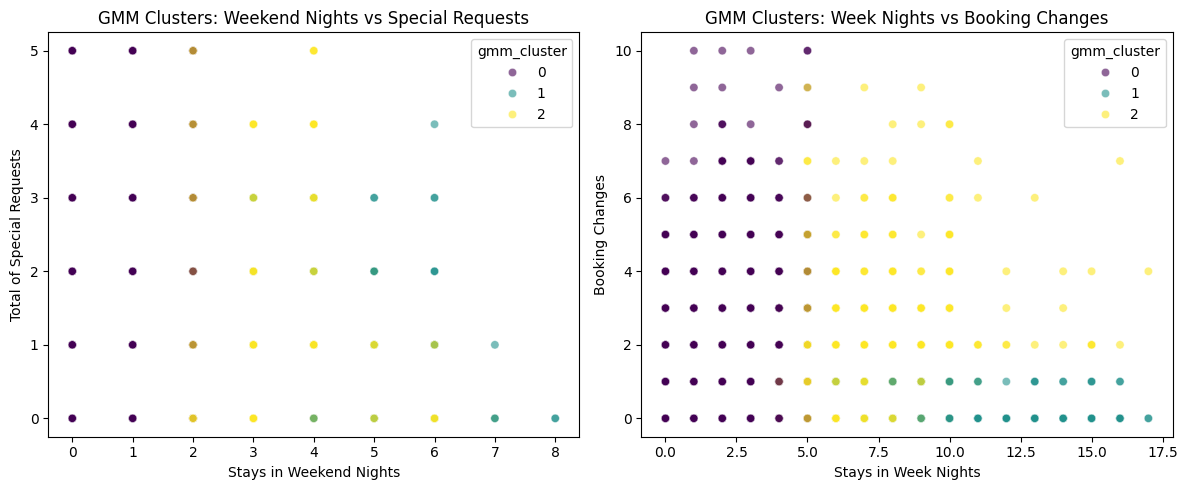


--- GMM Cluster Averages (Summary Table) ---


,stays_in_weekend_nights,stays_in_week_nights,booking_changes,total_of_special_requests
gmm_cluster,,,,
0,0.908654,2.350962,2.971154,1.906250
1,3.155963,8.142202,0.302752,0.935780
2,3.116935,7.552419,2.834677,1.544355


In [ ]:
# 1. Fit a Gaussian Mixture Model (choosing 3 clusters to match the K-Means setup)
gmm = GaussianMixture(n_components=3, random_state=42)

# Fit the model
gmm.fit(prepared_df[features])

# Predict probabilities (soft clusters)
# This returns an array of shape (n_samples, n_clusters) with the probability of each point belonging to each cluster
probs = gmm.predict_proba(prepared_df[features])

# To visualize and summarize, we assign each point to the cluster with the highest probability
prepared_df['gmm_cluster'] = gmm.predict(prepared_df[features])

# Add the probabilities as columns for reference
for i in range(3):
    prepared_df[f'gmm_prob_cluster_{i}'] = probs[:, i]

# 2. Visualize the GMM clusters with a scatterplot of stays_in_weekend_nights vs total_of_special_requests
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(
    x='stays_in_weekend_nights',
    y='total_of_special_requests',
    hue='gmm_cluster',
    palette='viridis',
    data=prepared_df,
    alpha=0.6
)
plt.title('GMM Clusters: Weekend Nights vs Special Requests')
plt.xlabel('Stays in Weekend Nights')
plt.ylabel('Total of Special Requests')

# 3. Do a second visualization using stays_in_week_nights vs booking_changes
plt.subplot(1, 2, 2)
sns.scatterplot(
    x='stays_in_week_nights',
    y='booking_changes',
    hue='gmm_cluster',
    palette='viridis',
    data=prepared_df,
    alpha=0.6
)
plt.title('GMM Clusters: Week Nights vs Booking Changes')
plt.xlabel('Stays in Week Nights')
plt.ylabel('Booking Changes')

plt.tight_layout()
plt.show()

# 4. Create a summary table showing the averages for each variable, broken out by GMM cluster
gmm_summary_table = prepared_df.groupby('gmm_cluster')[features].mean()
print("\n--- GMM Cluster Averages (Summary Table) ---")
display(gmm_summary_table)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. In the GMM results, clsuter 2 customers seem to be more prone to change. The cluster now spreads more to the right.

2. This might help answer the question:
Are our moderate stay customers prone to making booking changes and if so, how can we make sure to prevent loss and lower customer satisfaction.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [ ]:
# Calculate evaluation metrics for K-Means
kmeans_wcss = kmeans.inertia_
kmeans_silhouette = silhouette_score(prepared_df[features], prepared_df['cluster'])
kmeans_db_index = davies_bouldin_score(prepared_df[features], prepared_df['cluster'])

# Calculate evaluation metrics for GMM
# WCSS (Inertia) is not directly defined for GMM, but we can compute the sum of squared distances of points to their closest GMM cluster centroid.
gmm_centroids = []
for i in range(3):
    gmm_centroids.append(prepared_df[prepared_df['gmm_cluster'] == i][features].mean().values)
gmm_centroids = np.array(gmm_centroids)

# Map each point to its assigned GMM cluster centroid
closest_centroids = gmm_centroids[prepared_df['gmm_cluster']]
gmm_wcss = np.sum((prepared_df[features].values - closest_centroids) ** 2)

gmm_silhouette = silhouette_score(prepared_df[features], prepared_df['gmm_cluster'])
gmm_db_index = davies_bouldin_score(prepared_df[features], prepared_df['gmm_cluster'])

# Print metrics comparison table
print("--- Model Evaluation Metrics Comparison ---")
metrics_df = pd.DataFrame({
    'Metric': ['Within-Cluster Sum of Squares (WCSS)', 'Silhouette Score (higher is better)', 'Davies-Bouldin Index (lower is better)'],
    'K-Means': [kmeans_wcss, kmeans_silhouette, kmeans_db_index],
    'GMM': [gmm_wcss, gmm_silhouette, gmm_db_index]
})
display(metrics_df)

--- Model Evaluation Metrics Comparison ---


,Metric,K-Means,GMM
0,Within-Cluster Sum of Squares (WCSS),8721.887329,12457.355605
1,Silhouette Score (higher is better),0.338971,0.211192
2,Davies-Bouldin Index (lower is better),1.011584,2.240879


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. The K-Means model has better metrics.

5.3. I think it depends on the variables. For a simple and clear analysis, I would say K-Means is faster if we know there isn't too much variation. GMM is better when there is need to incorporate uncertainty.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [ ]:
# 1. Compute the average characteristics for each K-Means cluster
cluster_stats = prepared_df.groupby('cluster')[features].mean()

# 2. Sort the clusters by stays_in_week_nights to make differences clearer
sorted_cluster_stats = cluster_stats.sort_values(by='stays_in_week_nights')

print("--- Sorted Cluster Characteristics (Sorted by Week Night Stays) ---")
display(sorted_cluster_stats)

--- Sorted Cluster Characteristics (Sorted by Week Night Stays) ---


,stays_in_weekend_nights,stays_in_week_nights,booking_changes,total_of_special_requests
cluster,,,,
0,1.001980,2.566337,2.748515,1.752475
2,3.044521,7.541096,1.845890,1.438356
1,5.223529,13.270588,0.917647,0.882353


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧

1. The segments represent guest average stays, short stays, moderate stays and longer stays. It also sees their likelihood for making changes to their booking and likelihood of making special requests.

2. The hotel could tailor services in its booking policies, specifically to make them more flexible so that it's easier to work with customers and therefore keeping customer satisfaction.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The most challenging part was picking the right number of clusters and also deciding if the variables were right for the analysis.

2. I would use clustering when I want to discover patterns in a dataset and not answer a specific question as in supervised models.

3. I would say: Clustering will help us discover groupings and patterns that we may not have even known existed. It can help us know our customers better and that will help with customer satisfaction and in turn revenue.

4. One of my goals was to try and reinforce analytical statistical concepts and I think this relates to that outcome.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [1]:
!jupyter nbconvert --to html "IS4487_Shingi_assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook IS4487_Shingi_assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 565471 bytes to IS4487_Shingi_assignment_09_clustering.html
